# Ray Data: groupby and aggregate

Groups rows by a key and computes Count and Sum per group with Ray Data built-in aggregations.

**When to use it.** Per-key statistics over large tables: totals per customer, counts per category.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

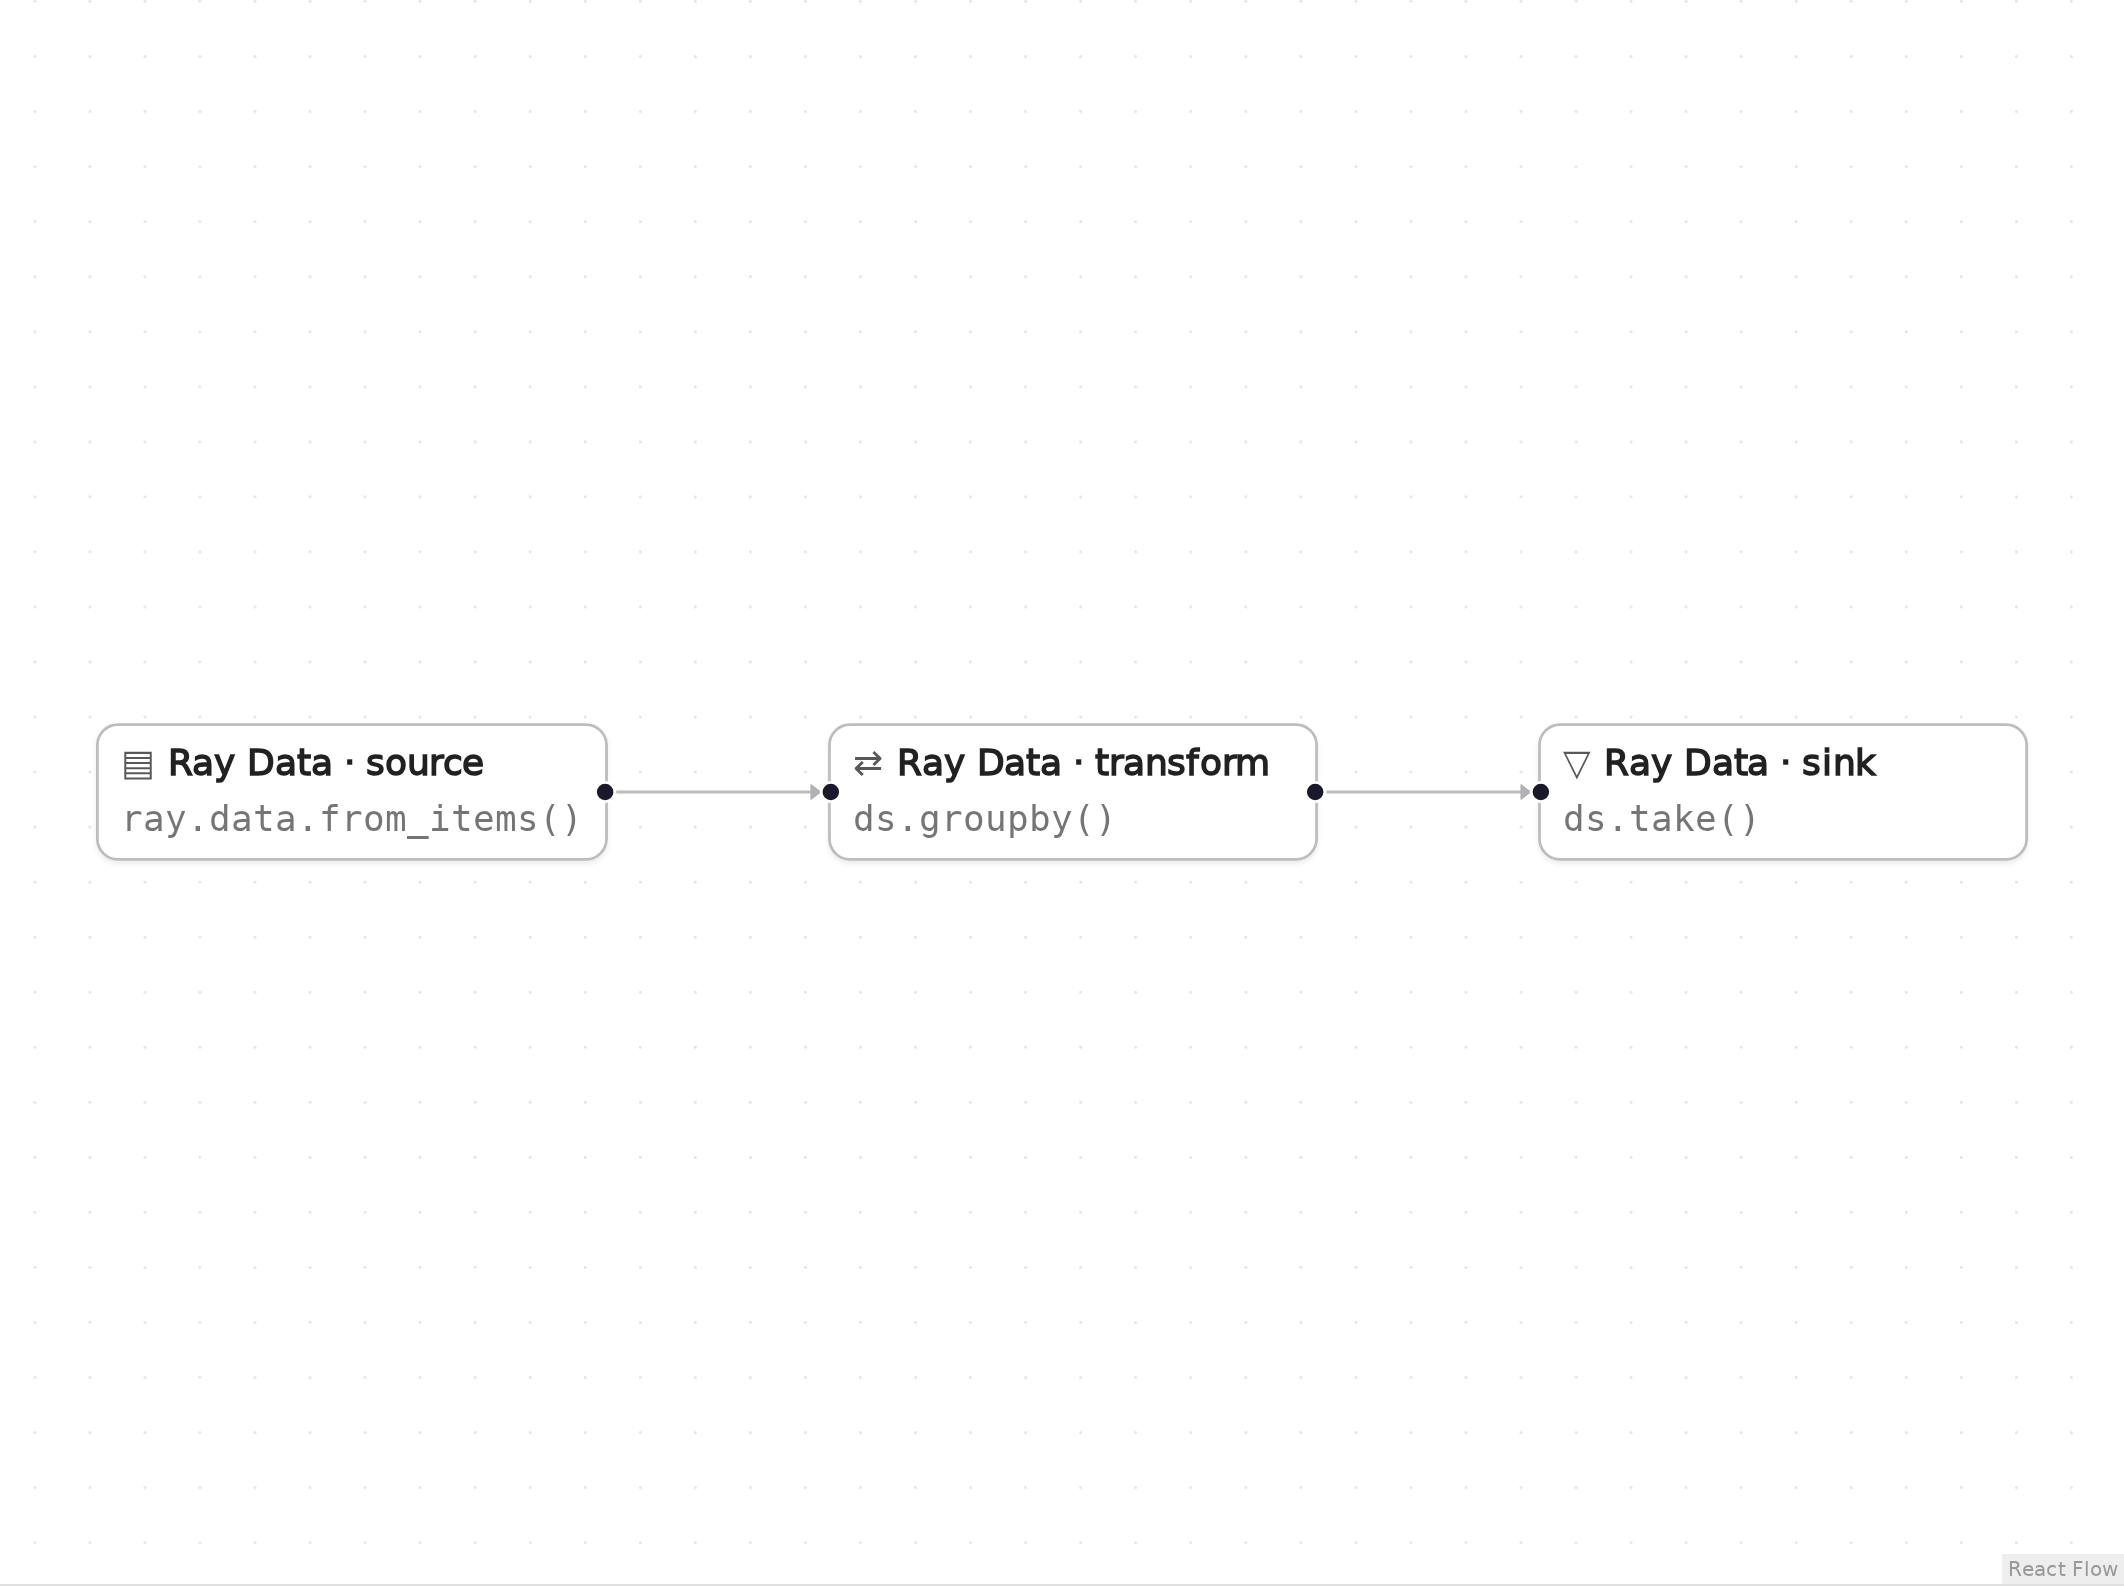

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions: Count and Sum are Ray Data built-ins.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray
from ray.data.aggregate import Count, Sum

if not ray.is_initialized():
    ray.init()

ds = ray.data.from_items([{"g": "a", "v": 1}, {"g": "a", "v": 3}, {"g": "b", "v": 5}])
ds = ds.groupby("g").aggregate(Count(), Sum("v"))
agg = ds.take(5)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
by_group = {r["g"]: (r["count()"], r["sum(v)"]) for r in agg}
assert by_group == {"a": (2, 4), "b": (1, 5)}, by_group
print(by_group)

{'b': (1, 5), 'a': (2, 4)}


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.data.aggregate import Count, Sum
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 9)

```python
ds = ray.data.from_items([{"g": "a", "v": 1}, {"g": "a", "v": 3}, {"g": "b", "v": 5}])
```

from_items builds a small in-memory dataset.

**Transform** (node `n2`, line 10)

```python
ds = ds.groupby("g").aggregate(Count(), Sum("v"))
```

groupby("g").aggregate(Count(), Sum("v")) shuffles rows by key and aggregates each group.

**Sink** (node `n3`, line 11)

```python
agg = ds.take(5)
```

take(5) returns up to five result rows as dicts.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()